In [67]:
from src_no_int import *
import scipy
from scipy.cluster.hierarchy import fclusterdata
from tqdm.auto import tqdm
from scipy.integrate import quad

# functions

In [8]:
def V(R, Omega):
    B = Omega * R2 ** 2 / (R2 ** 2 / R1 ** 2 - 1)
    return(0.5  * (B ** 2/ R ** 2 * (np.log(R2/R) - v0/B * R2) ** 2 - v0 ** 2))

In [68]:
def integrand(phi, A):
    return -1/(A - np.sin(phi)/2/beta)

## import

In [3]:
def load_output(filename):
    times = []
    Rs_list = []
    ps_list = []

    with open(filename, "r") as f:
        while True:
            line = f.readline()
            if not line:
                break  # EOF

            if line.startswith("ITEM: TIMESTEP"):
                # timestep
                t = float(f.readline().strip())
                times.append(t)

                # number of atoms
                f.readline()  # "ITEM: NUMBER OF ATOMS"
                N = int(f.readline().strip())

                # header
                f.readline()  # "ITEM: ATOMS id x y z vx vy vz"

                R_block = np.zeros((N, 3))
                p_block = np.zeros((N, 3))

                for i in range(N):
                    parts = f.readline().strip().split()
                    idx = int(parts[0])  # atom id
                    R_block[idx] = [float(x) for x in parts[1:4]]
                    p_block[idx] = [float(x) for x in parts[4:7]]

                Rs_list.append(R_block)
                ps_list.append(p_block)

    # convert lists to numpy arrays
    times = np.array(times)
    Rs_sol = np.array(Rs_list)  # shape (timesteps, N, 3)
    ps_sol = np.array(ps_list)  # shape (timesteps, N, 3)

    return times, Rs_sol, ps_sol



## Plotters

In [20]:
def plot_density(Omegas, depletion = False):
    fig, axs = plt.subplots(len(Omegas)//5, 5, figsize = (15,9.3))
    for i, Omega in tqdm(enumerate(Omegas)):
        file = f"no_int/{Omega}o_{N}n_{dt}dt_{steps}steps_noisy.txt"
        ps, Rs, t = load_output(file)
        steady = Rs[-40000:-1:100, :, :]
        coords = steady.reshape((40000,3))
        psi = np.arctan2(coords[:, 1], coords[:, 0])
        r = np.linalg.norm(coords[:, :2], axis = 1)
        axs[i // 5, i % 5].hist2d(coords[:, 0], coords[:, 1], bins = 40, range = [[-R2, R2], [-R2, R2]])
        axs[i // 5, i % 5].axis('equal')
        if i//5 == len(Omegas)//5 - 1:
            axs[i // 5, i % 5].set_xlabel('x')
        if i%5 == 0:
            axs[i // 5, i % 5].set_ylabel('y')
        axs[i // 5, i % 5].set_title(r'$\Omega = $'+f'{Omegas[i]:.2f}')   
        angle = np.linspace(-np.pi, np.pi, 100)
        axs[i // 5, i % 5].plot(R1 * np.cos(angle), R1 * np.sin(angle), color = 'white')
        axs[i // 5, i % 5].plot(R2 * np.cos(angle), R2 * np.sin(angle), color = 'white')
        if depletion:
            if Omega > 1.98:
                R_dep = scipy.optimize.fsolve(V, R1, args = Omegas[i], xtol=1e-06, maxfev=500)
                axs[i // 5, i % 5].plot(R_dep[0] * np.cos(angle), R_dep[0] * np.sin(angle), color = 'red')
        approx_R = get_params(Omegas[i])[1] / v0
        #axs[i // 5, i % 5].plot(approx_R * np.cos(angle), approx_R * np.sin(angle), color = 'red')
    fig.suptitle('Density')
    plt.show()

# Runs

In [10]:
kx = np.array([1, 0, 0]) # up vector
k0 = np.array([0, 0, 0])

In [74]:
N = 100
p0s, R0s = initialize_positions(N)
Omega = 0.1
dt = 0.1
steps = 50000
file = f"no_int/{Omega}o_{N}n_{dt}dt_{steps}steps_noisy.txt"

In [84]:
N = 1
p0s, R0s = initialize_positions(N)
Omega = 3
dt = 0.1
steps = 50000
file = f"no_int/{Omega}o_{N}n_{dt}dt_{steps}steps_noisy.txt"

ps_sol, Rs_sol, t = solver(Omega, kx, euler, N, p0s, R0s, dt, steps, file, noise = True)

Tumbling period: 208.0543590107162


  0%|          | 0/49999 [00:00<?, ?it/s]

No tumbling


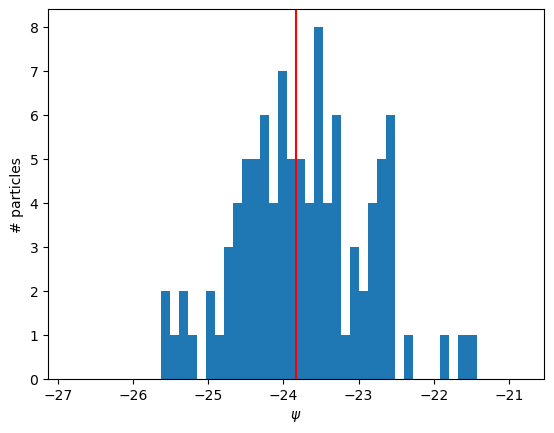

In [75]:
ps_sol, Rs_sol, t = load_output(file)
A, B, omega = get_params(Omega)
plot_angle(A, Rs_sol, 50)

No tumbling


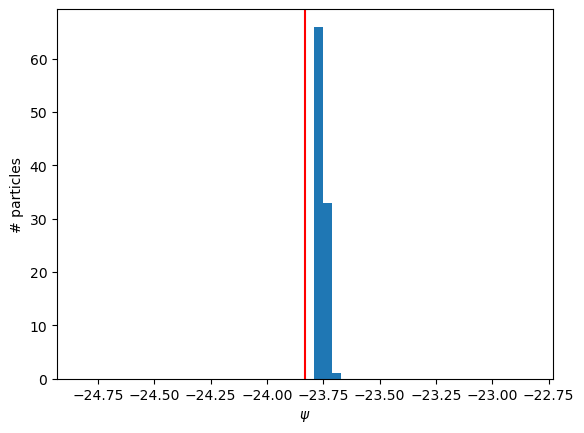

In [76]:
file = f"no_int/{Omega}o_{N}n_{dt}dt_{steps}steps.txt"
ps_sol, Rs_sol, t = load_output(file)
A, B, omega = get_params(Omega)
plot_angle(A, Rs_sol, 50, delta=1)

In [12]:
Omegas = [0., 0.1, 0.2, 0.3, 0.4, 1., 2., 3., 4., 5., 6., 7., 8., 9., 10.]
for Omega in Omegas:
    print(f'Omega = {Omega}')
    file = f"no_int/{Omega:.1f}o_{N}n_{dt}dt_{steps}steps_noisy.txt"
    ps_sol, Rs_sol, t = solver(Omega, kx, euler, N, p0s, R0s, dt, steps, file, noise = True)

    


Omega = 0.0
No tumbling


  0%|          | 0/49999 [00:00<?, ?it/s]

Omega = 0.1
No tumbling


  0%|          | 0/49999 [00:00<?, ?it/s]

Omega = 0.2
No tumbling


  0%|          | 0/49999 [00:00<?, ?it/s]

... (20 outputs left out)

Omega = 9.0
Tumbling period: 69.14118733515862


  0%|          | 0/49999 [00:00<?, ?it/s]

Omega = 10.0
Tumbling period: 62.222595074664795


  0%|          | 0/49999 [00:00<?, ?it/s]

0it [00:00, ?it/s]

No tumbling
No tumbling
No tumbling
Tumbling period: 3668.963147012449
Tumbling period: 1979.5216443064755
Tumbling period: 642.0096170469793
Tumbling period: 313.4268510611466
Tumbling period: 208.0543590107162
Tumbling period: 155.8073778597314
Tumbling period: 124.55976395549156
Tumbling period: 103.76087295819339
Tumbling period: 88.91778887152803
Tumbling period: 77.79165540971741
Tumbling period: 69.14118733515862
Tumbling period: 62.222595074664795


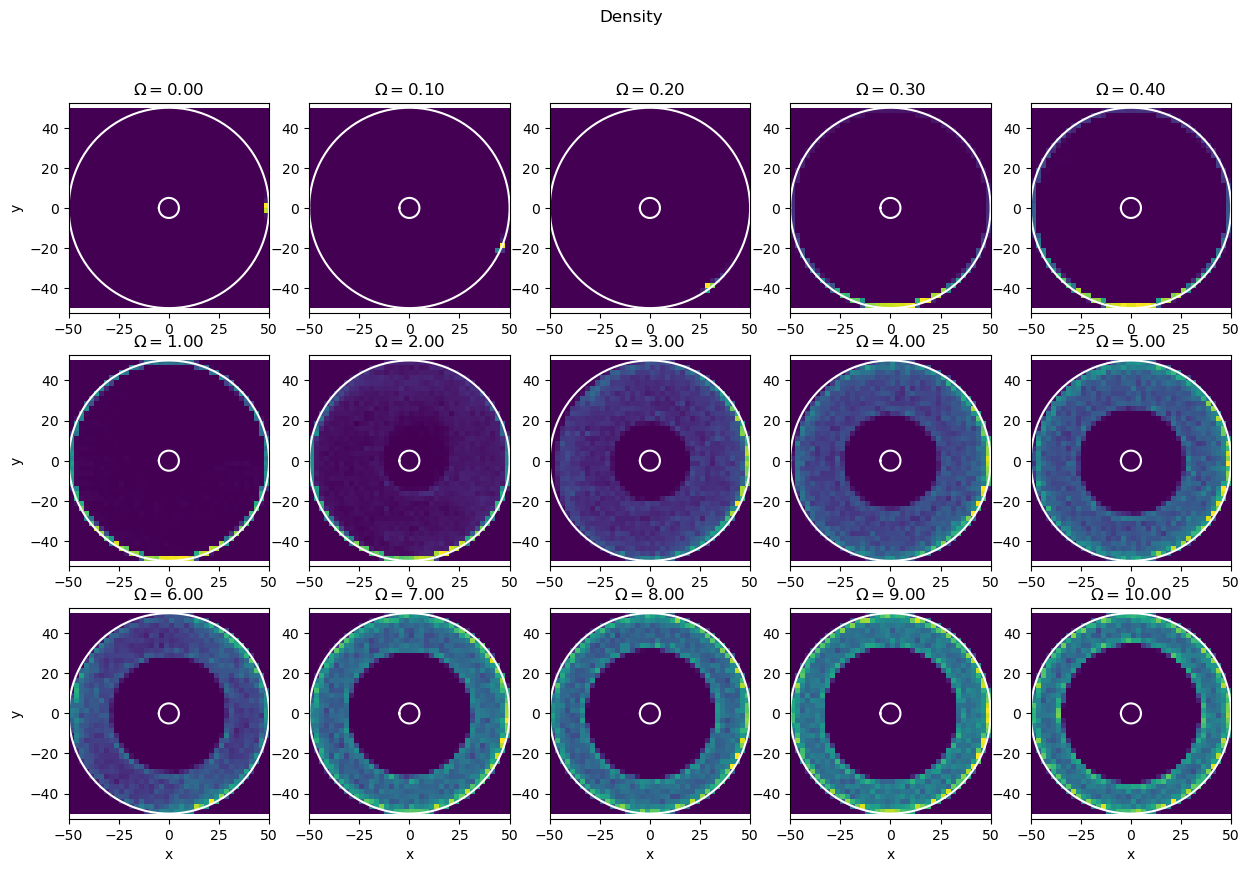

In [21]:
plot_density(Omegas)

### Distribution

In [45]:
file = '/Users/dzinty/Desktop/microswimmers/no_int/0.4o_100n_0.1dt_50000steps_noisy.txt'
ps_sol, Rs_sol, t = load_output(file)

Tumbling period: 1979.5216443064755
1979.521644306475


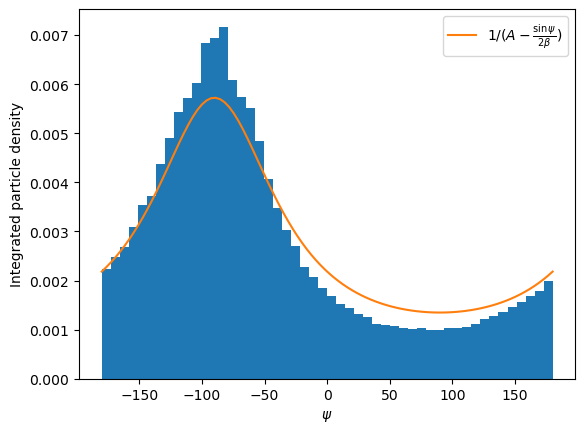

In [71]:
A, B, omega = get_params(0.4)
steady = Rs_sol[-40000:-1:100, :, :]
coords = steady.reshape((40000,3))
psi = np.arctan2(coords[:, 1], coords[:, 0]) * 180 / np.pi
if -1 < (2 * A * beta) and (2 * A * beta) < 1:
    phi_star = np.arcsin(2 * A * beta) * 180 / np.pi
    plt.axvline(phi_star, color = 'r')
plt.hist(psi, bins = 50, density=True)
psis = np.linspace(np.min(psi), np.max(psi), 100)
I, err = quad(integrand, -np.pi, np.pi, args = (A))
print(I)
plt.plot(psis, integrand(psis * np.pi/180, A) / I /180*np.pi , label = r'$1/(A - \frac{\sin\psi}{2\beta})$')
plt.xlabel(r'$\psi$')
plt.ylabel(f'Integrated particle density')
plt.legend()
plt.show()

Tumbling period: 3668.963147012449
3668.9631470124505


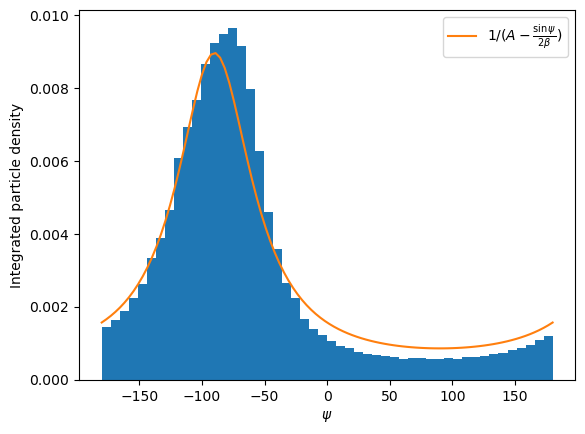

In [73]:
file = '/Users/dzinty/Desktop/microswimmers/no_int/0.3o_100n_0.1dt_50000steps_noisy.txt'
ps_sol, Rs_sol, t = load_output(file)
A, B, omega = get_params(0.3)
steady = Rs_sol[-40000:-1:100, :, :]
coords = steady.reshape((40000,3))
psi = np.arctan2(coords[:, 1], coords[:, 0]) * 180 / np.pi
if -1 < (2 * A * beta) and (2 * A * beta) < 1:
    phi_star = np.arcsin(2 * A * beta) * 180 / np.pi
    plt.axvline(phi_star, color = 'r')
plt.hist(psi, bins = 50, density=True)
psis = np.linspace(np.min(psi), np.max(psi), 100)
I, err = quad(integrand, -np.pi, np.pi, args = (A))
print(I)
plt.plot(psis, integrand(psis * np.pi/180, A) / I /180*np.pi , label = r'$1/(A - \frac{\sin\psi}{2\beta})$')
plt.xlabel(r'$\psi$')
plt.ylabel(f'Integrated particle density')
plt.legend()
plt.show()

### Depletion zone

In [38]:
Omegas[6:]

[2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0]

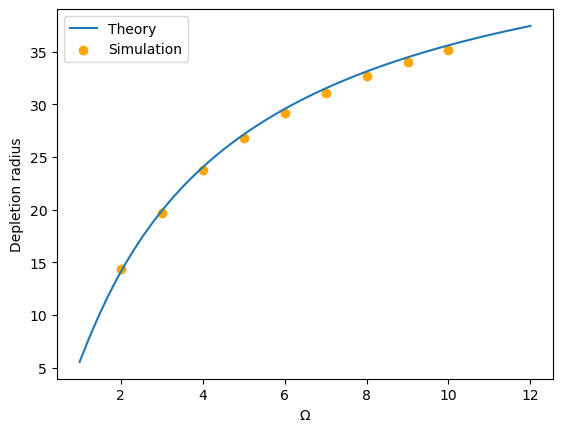

In [40]:
ws = np.linspace(1, 12, 50)
Rdeps = []
for w in ws:
    R_dep = scipy.optimize.fsolve(V, R1, args = w, xtol=1e-06, maxfev=500)
    Rdeps.append(R_dep[0])
plt.plot(ws, Rdeps, label = 'Theory')
r_mean = []
r_std = []
for Omega in Omegas[6:]:
    file = f"no_int/{Omega}o_{N}n_{dt}dt_{steps}steps_noisy.txt"
    ps, Rs, t = load_output(file)
    steady = Rs[-40000:-1:100, :, :]
    coords = steady.reshape((40000,3))
    r = np.linalg.norm(coords[:, :2], axis = 1)
    r = np.sort(r)
    r_mean.append(np.mean(r[:100]))
    r_std.append(np.std(r[:100]))


#plt.errorbar(Omegas[6:], r_mean, r_std, color = 'orange', label = 'Simulation')
plt.scatter(Omegas[6:], r_mean, color = 'orange', label = 'Simulation')
plt.xlabel(r'$\Omega$')
plt.ylabel('Depletion radius')
plt.legend()

### Orientation

(np.float64(-50.875242597179046),
 np.float64(54.03158915414009),
 np.float64(-54.1364028582916),
 np.float64(54.24117548658314))

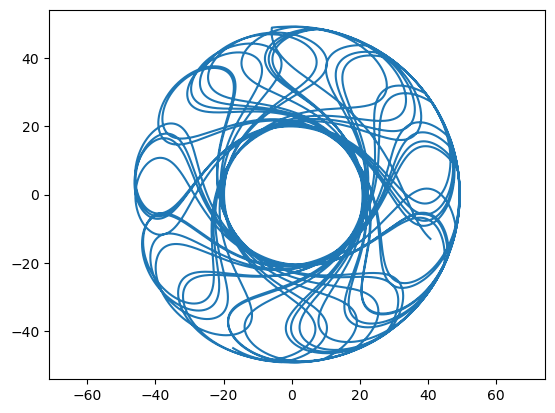

In [89]:
file = '/Users/dzinty/Desktop/microswimmers/no_int/3o_1n_0.1dt_50000steps_noisy.txt'
ps_sol, Rs_sol, t = load_output(file)
plt.plot(Rs_sol[:, 0, 0], Rs_sol[:, 0, 1])
plt.axis('equal')

In [91]:
ps_sol[:, 0, 1]

IndexError: too many indices for array: array is 1-dimensional, but 3 were indexed

In [ ]:
phi = np.arctan2(ps_sol[:, 0, 1], ps_sol[:, 0, 0])
plt.plot(t, phi)

IndexError: too many indices for array: array is 1-dimensional, but 3 were indexed

In [81]:
A, B, omega = get_params(3)
alpha = 2 * A * beta


Tumbling period: 208.0543590107162
